In [1]:
pip install -U mplhep

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)
from sidm.tools import utilities #scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()

In [3]:
channels = ["cr_Zmumu",
            "cr_Zmumu_noLJ_noMu_cut"
           ]

In [6]:
sum_hist = {"data" : {}, "DY":{}}
data = functions.get_data_files()
data =  [x for x in data if "C" in x]
TT = functions.get_bg_file_names("TTJets")
DY = functions.get_bg_file_names("DYJetsToLL")
QCD = functions.get_bg_file_names("QCD")
DB = functions.get_bg_file_names("Diboson")

for channel_name in channels:
    folder_name = f"OutputFiles/{channel_name}"
    sum_hist["data"][channel_name] =utilities.sum_hist(data, folder_name)
    sum_hist["DY"][channel_name] =  utilities.sum_hist(DY, folder_name)

In [ ]:
# title_name= "1 LJ CR" # title = r"1 LJ CR $\eta-\phi$ Veto"
# ratio  = 6.616/62.061775847
# # ratio = 1
# channel_name = "cr_Zmumu_noLJ_noMu_cut" ##chnage the selection depending on what you want to plot 
# #"cr_1egmOr1mu_lj"


# sum_data_all= utilities.sum_hist(data, folder_name)
# summed_QCD = utilities.sum_hist(QCD, folder_name)
# summed_TT  = utilities.sum_hist(TT,  folder_name)
# summed_DY  = utilities.sum_hist(DY, folder_name)
# # summed_DB  = utilities.sum_hist(DB,  folder_name)

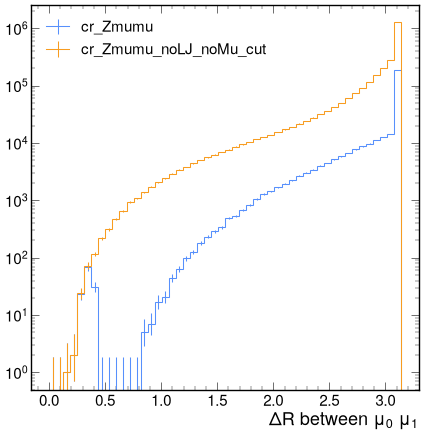

In [10]:
import matplotlib.pyplot as plt
histogram_name = "mu0_mu1_dR"
for channel_name  in channels:
    histogram = sum_hist["data"][channel_name][histogram_name][channel_name, :]
    utilities.plot(histogram, label=channel_name, skip_label=True)
plt.yscale("log")
plt.legend()
plt.show()

In [ ]:
for x in sum_data_all.keys():
    print(f"'{x}',")

In [ ]:
def plot(histogram_list, binning=1j):
    functions.plot_DataMC(histogram_list,
                      channel_name, 
                      summed_QCD, 
                      summed_TT, 
                      summed_DY, 
                      # summed_DB, 
                      sum_data_all, 
                      ratio, binning=binning, 
                      file_name=f"{channel_name}_lj_pt", 
                         lumi=6.616)

In [ ]:
histogram_list  = [ 
'mu_lj_pt',
"mu_lj_pfMu_n",
"mu_lj_muonN"
]
plot(histogram_list)

In [ ]:
histogram_list  = [ 
'mu0_mu1_pt',
'mu0_mu1_dR',
'mu0_mu1_dphi'
]
plot(histogram_list)

In [ ]:
histogram_list  = [ 
'jet0_muLj0_dR',
'jet1_muLj0_dR',
    'jet0_muLj0_dPhi',
]
plot(histogram_list, binning =2j)

In [ ]:
histogram_list  = [ 
'jet0_muLj0_dR',
'jet1_muLj0_dR',
]
plot(histogram_list)

In [ ]:
histogram_list  = [ 
'jet_n',
'jet_pt',
'mu_lj_pt',
    
]
plot(histogram_list)

In [ ]:
histogram_list  = [ 
"mu_lj_pfMu_max_trkNumPixelHits",
 "mu_lj_pfMu_min_trkNumPixelHits",
"mu_lj_pfMu_min_trkNumTrkLayers"
]
plot(histogram_list)

In [ ]:

histogram_list  = [ 
'muon_muon_invmass',
]
plot(histogram_list, binning =2j)


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def plot2D(histogram_list, binning=1j):
    for i, histogram_name in enumerate(histogram_list):
        fig, axs =plt.subplots(1, 2, figsize=(30, 12))
        ax=axs[0]
        histogram = sum_data_all[histogram_name][channel_name, ::binning, ::binning]
        utilities.plot(histogram, skip_label=True, ax = ax, norm=LogNorm())
        ax=axs[1]
        histogram = summed_DY[histogram_name][channel_name, ::binning, ::binning]
        utilities.plot(histogram, skip_label=False, ax = ax, norm=LogNorm())
        plt.show()
        plt.close()

In [ ]:
histogram_list = ['jet_eta_phi',
    'muon_eta_phi',
]

plot2D(histogram_list, binning=1j)


In [ ]:
histogram_list = ['jet0Pt_diMuon_dR',
'jet0Pt_diMuon_pt',
'jet0Pt_diMuon_dPhi',
'jet0Pt_muLj0_pt',
                  
'jet1Pt_muLj0_pt',
'mu0_mu1_dphi_invMass',
    
]

plot2D(histogram_list)
